# Analysis AI-Team

### Load and import 

In [33]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

# --- General libraries --------------------------------------------------
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px          # interactive world map
import plotly.graph_objects as go    # confusion arcs, custom figures
from IPython.display import display
import torch

# --- Shared setup -------------------------------------------------------
from shared.data import Config, CountryMapper, OSV5MDataset, MetadataDecoder
from shared.models import (GeoCLIPModel, PredictionRunner, Segmenter, TextDetector,
                           Inpainter, fit_image, fit_mask, free_gpu_memory, get_device)
from shared.masking import MaskApplier
cfg = Config()

# --- Load groups own py files -------------------------------------------------------
import importlib
import importlib, pair_a.q1_errorstructure as q1
from pair_a import q3_visualcues as q3


print("PyTorch", torch.__version__, "| CUDA build", torch.version.cuda)
device = get_device(cfg.device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    torch.cuda.reset_peak_memory_stats()
    
# ---------------- change settings here ----------------
cfg.images_per_country = 50
cfg.use_clip_baseline = False        # True -> downloads the original CLIP once (~1.7 GB)
cfg.crop_mode = "center_crop"        # "center_crop" | "pad" | "squash"
cfg.candidate_list = "v1"            # "v1" | "all_test_locations"
cfg.fill_mode = "gray"               # "gray" | "blur" | "inpaint" (inpaint downloads LaMa, ~200 MB)
cfg.batch_size = 32
cfg.num_workers = 4                  # set to 0 if image loading hangs (e.g. on Windows)
# ------------------------------------------------------

cfg.check()
cfg.show()

mapper = CountryMapper("resources/country_aliases.csv")
dataset = OSV5MDataset(cfg, mapper).load()      # no download, already on disk
decoder = MetadataDecoder()

run_name = f"streetclip_{cfg.candidate_list}_{cfg.crop_mode}"   # streetclip_v1_center_crop
preds, logits, embeds, info = PredictionRunner.load(f"results/shared/{run_name}")
preds = decoder.decode(preds)        # adds climate / land-cover / drive-side names

pilot_ids = dataset.build_pilot()    # loads the shared resources/pilot_ids.csv
print(f"{len(preds):,} predictions | {len(pilot_ids):,} pilot images | model: {info['model']}")

PyTorch 2.11.0+cu128 | CUDA build 12.8
GPU: NVIDIA GeForce RTX 5070
seed                   42
device                 auto
data_dir               data
results_dir            results
resources_dir          resources
images_per_country     50
streetclip_model       geolocal/StreetCLIP
use_clip_baseline      False
clip_model             openai/clip-vit-large-patch14-336
prompt_template        A Street View photo in {country}, {subregion}.
candidate_list         v1
crop_mode              center_crop
batch_size             32
num_workers            4
half_precision         True
top_k                  10
segmentation_model     facebook/mask2former-swin-large-mapillary-vistas-semantic
fill_mode              gray
blur_radius            25
mask_dilation_px       5
num_random_controls    3
lama_url               https://github.com/enesmsahin/simple-lama-inpainting/releases/download/v0.1.0/big-lama.pt
210,122 predictions | 9,578 pilot images | model: geolocal/StreetCLIP


# Q1: Error structure and geography 
Which countries are confused, what do confused pairs share, are there attractor countries, do errors cluster geographically?

In [6]:
importlib.reload(q1)

preds_df = preds.loc[preds["representable"]].copy()
country_meta_df = mapper.table.reset_index().copy()

q1_cfg = q1.Q1Config(
    true_col="country_id",
    pred_col="pred_1",
    topk_cols=["pred_1", "pred_2", "pred_3", "pred_4", "pred_5"],

    image_id_col="id",
    lat_col="latitude",
    lon_col="longitude",

    meta_country_col="iso2",
    meta_code_col="iso2",
    continent_col="continent",
    subregion_col="world_subregion",
    neighbors_col="neighbors",

    meta_lat_col="center_lat",
    meta_lon_col="center_lng",

    scalar_attrs=("driving_side", "landlocked"),
    list_attrs=("languages",),
    list_sep=";",

    min_n=20,
    n_permutations=1000,
    seed=42,
)

data = q1.Q1DataBuilder(preds_df, country_meta_df, q1_cfg).build()
ana = q1.Q1Analyser(data)
rep = q1.Q1Reporter(ana)

rep.summary()

Q1 data summary
  images used:          208,314 (input rows 208,314)
  countries in test:    188 (175 with n >= 20)
  top-k available:      [1, 3, 5]
  overall error top-1:  0.509
  overall error top-3:  0.299
  overall error top-5:  0.220


,id,country_id,pred_1,prob_1,pred_2,prob_2,pred_3,prob_3,pred_4,prob_4,...,pred_continent,pred_subregion,same_continent,same_subregion,is_neighbor,hop_distance,same_driving_side,same_landlocked,shares_languages,km_distance
0,547473234108938,MG,AO,0.438144,MZ,0.250621,GW,0.089524,ZM,0.039236,...,AF,Middle Africa,1.0,0.0,0.0,NaN,1.0,1.0,0.0,3149.608772
1,826109781317024,KZ,KZ,0.337806,KG,0.213292,MN,0.176602,TM,0.087960,...,AS,Central Asia,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1006398440000844,IT,IT,0.334948,SM,0.314084,GR,0.048535,AD,0.045877,...,EU,Southern Europe,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2943891539215481,ML,KE,0.158321,SS,0.158221,SO,0.113120,ET,0.092340,...,AF,Eastern Africa,1.0,0.0,0.0,5.0,0.0,0.0,0.0,4926.167420
4,122945119799579,TH,TL,0.513203,ID,0.347534,TH,0.033007,PH,0.018554,...,OC,South-Eastern Asia,0.0,1.0,0.0,3.0,1.0,1.0,1.0,3896.458745
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
208309,311190247232610,SB,PG,0.296358,SB,0.196895,FM,0.112897,PW,0.072968,...,OC,Melanesia,1.0,1.0,0.0,NaN,1.0,1.0,1.0,1342.830048
208310,333786891410519,US,US,0.436412,CA,0.115343,MX,0.062468,BM,0.039069,...,NA,North America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
208311,947201369432368,US,US,0.757911,CG,0.023070,TH,0.021842,GE,0.013953,...,NA,North America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
208312,3975075185917527,US,US,0.843572,GL,0.069812,CA,0.039642,MN,0.017276,...,NA,North America,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


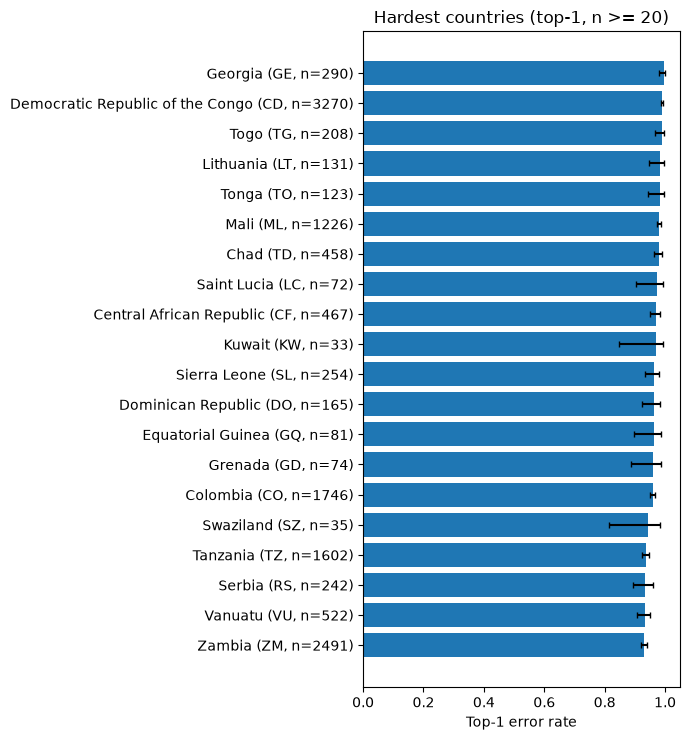

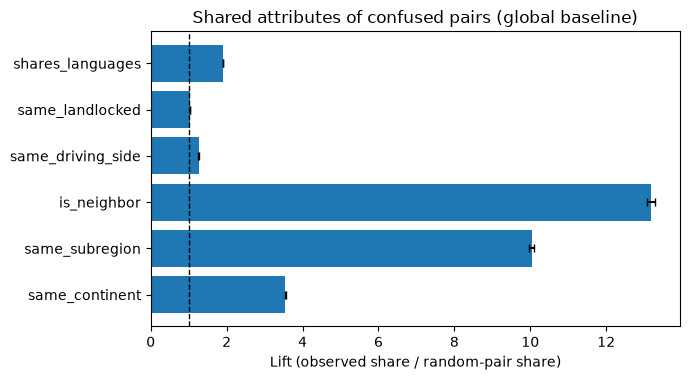

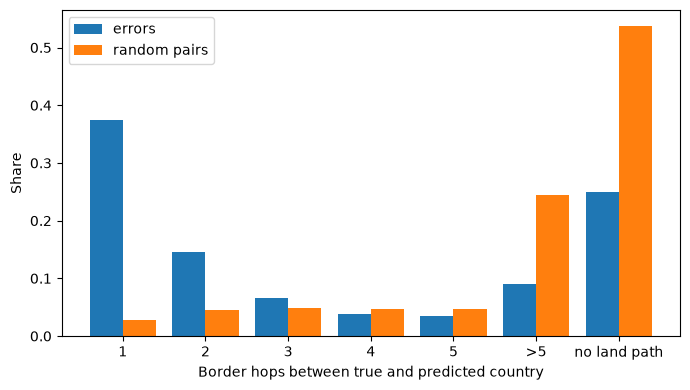

In [8]:
#rep.show(ana.difficulty_ranking(k=1), "Hardest countries", n=50)
#rep.show(ana.topk_comparison(), "Top-1 vs top-k")
#rep.show(ana.region_comparison("continent"), "Continents")
#rep.show(ana.top_confusion_pairs(n=20, min_count=5), "Top pairs A→B")
#rep.show(ana.attractors(), "Attractors")
#rep.show(ana.attractor_sources("DE"), "Germany's FP sources")

glob = ana.feature_baseline()                        # shared attributes vs random pairs
within = ana.feature_baseline(within_continent=True) # controls for continent
#rep.show(glob, "Shared attributes (global)"); rep.show(within, "Within continent")

#rep.show(ana.region_locality(), "Same region vs random")
#rep.show(ana.hop_distribution(), "Border hops vs random")
ana.morans_i()

rep.plot_difficulty(); rep.plot_feature_lift(glob); rep.plot_hop_distribution()

results = ana.run_all()       # everything at once as a dict
data.images                   # image-level table, keeps GPS

In [5]:
importlib.reload(q1)

dash_q1 = q1.Q1Dashboard(ana)   # computes all baselines once (takes a bit with 1000 permutations)
dash_q1.run()                   # opens inline under this cell

# dash_q1.run(mode="tab")       # same app in a new browser tab
# dash_q1.run(port=8051)        # if it says the port is already in use after a re-run

## Q2: Overconfidence and training coverage
When is the model confidently wrong, and can we infer which countries were in its Street View training?

In [11]:
from pair_a import q2_confidence as q2, viz

countries = mapper.table
clip_preds = pd.read_parquet("results/shared/clip_v1_center_crop/predictions.parquet")   # original CLIP

FileNotFoundError: results/shared/clip_v1_center_crop/predictions.parquet

### Q2.1 Calibration
- Is the top-1 probability an honest estimate of the accuracy?
- StreetCLIP vs. original CLIP (same model before the Street View fine-tuning)
- Lower panel: how many images are behind each point

,Images,Mean confidence,Accuracy,95 % CI
0% to 10%,"1,899",8.1 %,6.6 %,5.6 to 7.8 %
10% to 20%,"19,357",15.9 %,11.8 %,11.4 to 12.3 %
20% to 30%,"29,053",25.0 %,19.8 %,19.4 to 20.3 %
30% to 40%,"27,483",34.9 %,29.6 %,29.1 to 30.2 %
40% to 50%,"24,592",45.0 %,40.9 %,40.3 to 41.6 %
50% to 60%,"20,512",54.8 %,50.7 %,50.0 to 51.4 %
60% to 70%,"17,477",64.9 %,61.7 %,60.9 to 62.4 %
70% to 80%,"17,028",75.0 %,73.9 %,73.3 to 74.6 %
80% to 90%,"18,541",85.1 %,82.4 %,81.8 to 82.9 %
90% to 100%,"32,372",96.1 %,93.9 %,93.6 to 94.1 %


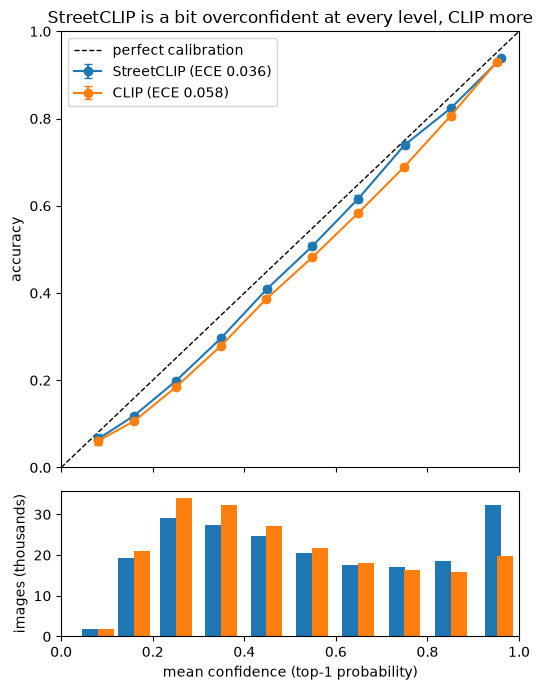

In [ ]:
cal = {"StreetCLIP": q2.calibration_table(preds), "CLIP": q2.calibration_table(clip_preds)}
display(viz.show_table(cal["StreetCLIP"], {"n": "Images", "conf": "Mean confidence", "acc": "Accuracy"},
                       pct=["conf", "acc"], ci=("acc", "ci_low", "ci_high"), bar="n"))
q2.plot_reliability(cal, "StreetCLIP is a bit overconfident at every level, CLIP more");

### Q2.2 Where is the model confidently wrong?
- Per country: overconfidence = mean confidence - accuracy (> 0: overconfident)
- Confident: top-1 probability >= 0.8

In [ ]:
sc_table = q2.country_table(preds, countries)
top_gap = sc_table[~sc_table.low_n].sort_values("gap", ascending=False).head(10)
display(viz.show_table(top_gap, {"name": "Country", "n": "Images", "acc": "Accuracy", "conf": "Mean confidence",
                                 "gap": "Overconfidence", "conf_wrong": "Confidently wrong"},
                       pct=["acc", "conf", "conf_wrong"], pts=["gap"], ci=("acc", "ci_low", "ci_high"), bar="gap",
                       index=False))
q2.plot_gap_map(sc_table).show()

Country,Images,Accuracy,95 % CI,Mean confidence,Overconfidence,Confidently wrong
Georgia,290,0.0 %,0.0 to 1.3 %,36.6 %,+36.6 pts,2.1 %
Kuwait,33,3.0 %,0.5 to 15.3 %,37.8 %,+34.8 pts,0.0 %
Estonia,274,15.3 %,11.5 to 20.1 %,49.0 %,+33.7 pts,11.3 %
Lithuania,131,2.3 %,0.8 to 6.5 %,35.1 %,+32.8 pts,0.0 %
Mali,"1,226",0.6 %,0.3 to 1.2 %,32.3 %,+31.7 pts,1.1 %
Swaziland,35,8.6 %,3.0 to 22.4 %,40.0 %,+31.4 pts,5.7 %
Zimbabwe,269,9.3 %,6.4 to 13.4 %,38.9 %,+29.6 pts,4.5 %
Yemen,497,6.4 %,4.6 to 8.9 %,35.3 %,+28.8 pts,1.2 %
Morocco,"1,266",9.4 %,7.9 to 11.1 %,38.2 %,+28.8 pts,1.3 %
Slovakia,150,8.0 %,4.6 to 13.5 %,36.3 %,+28.3 pts,0.7 %


In [ ]:
conf_err = q2.confident_errors(preds, countries)
q2.plot_confident_errors(conf_err, "Two US pairs make up 40 % of all confident errors: US -> Georgia and US -> Canada").show()

#### The Georgia case
- "Georgia" is a country (GE) and a US state
- Prompt for GE: "A Street View photo in Georgia." (template and country name from the StreetCLIP paper)
- Which US states are guessed as the country Georgia?
- Does the original CLIP (same prompt, before fine-tuning) make the same error?
- Images below: random, not hand-picked; shown as the model sees them (center crop)

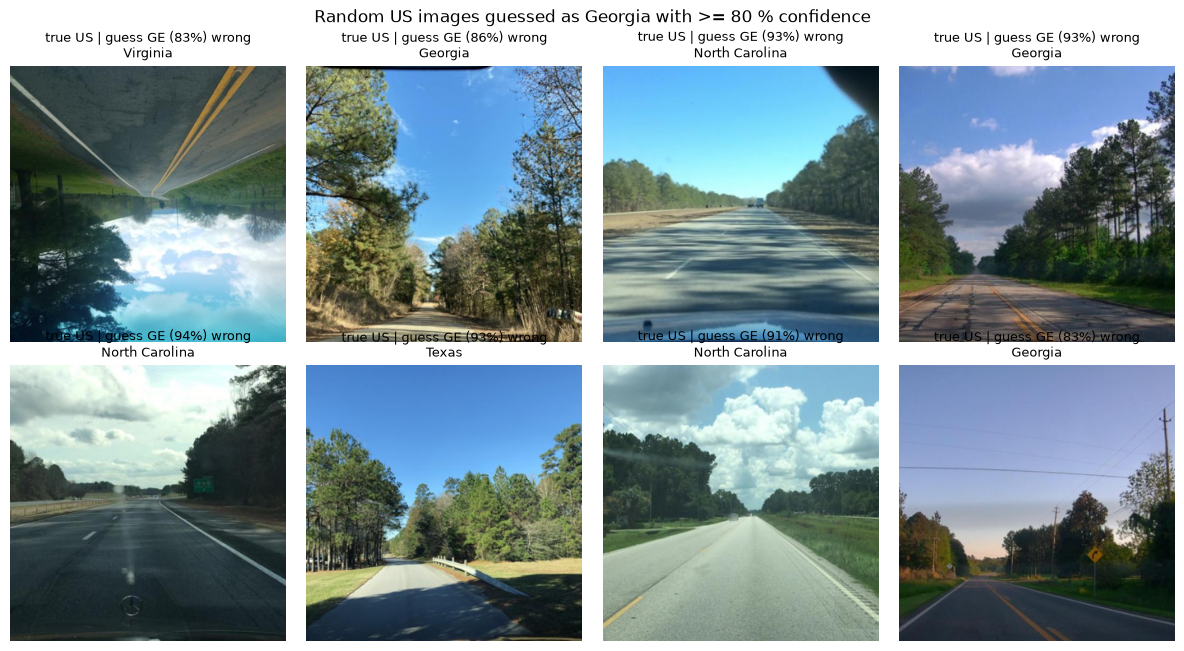

In [ ]:
q2.plot_georgia_map(q2.georgia_states(preds),
                    "The country \"Georgia\" is guessed for the US South-East (89 % of the state of Georgia)").show()
viz.image_grid(dataset, q2.confident_examples(preds, "US", "GE"),
               "Random US images guessed as Georgia with >= 80 % confidence", note="region");

In [ ]:
ge_cmp = q2.georgia_compare({"CLIP": clip_preds, "StreetCLIP": preds})   # same prompt for both models
display(viz.show_table(ge_cmp, {"us_to_ge": "US images guessed Georgia", "us_share": "Share of US images",
                                "us_to_ge_conf": "... with >= 80 % confidence",
                                "ge_guess_us": "Georgia guesses that are US",
                                "ge_right": "Real Georgia right", "ge_n": "Real Georgia images"},
                       pct=["us_share", "ge_guess_us"]))

,US images guessed Georgia,Share of US images,... with >= 80 % confidence,Georgia guesses that are US,Real Georgia right,Real Georgia images
CLIP,"1,962",8.2 %,634,89.7 %,4,290
StreetCLIP,"2,346",9.8 %,"1,126",96.3 %,0,290


- Low precision: a label the model picks often, but wrongly
- Grey rows: country has no test images, so every guess of it is an error

In [ ]:
pred_table = q2.predicted_table(preds, countries)
low_prec = pred_table[pred_table.n_pred >= 100].sort_values("precision").head(10)
display(viz.show_table(low_prec, {"name": "Guessed country", "n_pred": "Times guessed",
                                  "precision": "Right when guessed", "n_true": "Real test images"},
                       pct=["precision"], bar="n_pred", grey=low_prec.n_true == 0, index=False))

Guessed country,Times guessed,Right when guessed,Real test images
Georgia,"2,436",0.0 %,290
Gabon,740,0.0 %,7
Syria,793,0.0 %,1
Namibia,909,0.0 %,0
Guam,331,0.0 %,0
Andorra,196,0.0 %,0
San Marino,187,0.0 %,0
Nauru,286,0.0 %,0
Eritrea,169,0.0 %,13
Republic of the Congo,389,0.3 %,27


### Q2.3 Training coverage
- Paper's training list: uncertain evidence (says 101 countries, lists 92)
- Idea: countries in the Street View training should gain most from fine-tuning (CLIP -> StreetCLIP)
- Box plot: one dot = one country (hover for the name)

In [ ]:
groups = q2.training_groups(sc_table).rename(index={True: "on the paper's list", False: "not on the list"})
display(viz.show_table(groups, {"countries": "Countries", "images": "Images", "macro_acc": "Macro accuracy",
                                "acc_ci": "95 % CI (+/-)", "macro_conf": "Macro confidence",
                                "mean_gap": "Mean overconfidence"},
                       pct=["macro_acc", "acc_ci", "macro_conf"], pts=["mean_gap"]))
gain = q2.gain_table(sc_table, q2.country_table(clip_preds, countries))
q2.plot_gain_by_group(gain, "Countries on the list gain a bit more, but the two groups overlap a lot").show()
q2.plot_gain(gain).show()

,Countries,Images,Macro accuracy,95 % CI (+/-),Macro confidence,Mean overconfidence
not on the list,85,"48,476",28.7 %,4.4 %,37.4 %,+8.8 pts
on the paper's list,86,"159,576",46.8 %,5.3 %,51.5 %,+4.7 pts


In [ ]:
big = gain[~gain.low_n]
gain_cols = {"name": "Country", "n": "Images", "acc_clip": "CLIP", "acc": "StreetCLIP", "gain": "Gain"}
display(viz.show_table(big[~big.in_train_list].sort_values("gain", ascending=False).head(8), gain_cols,
                       pct=["acc_clip", "acc"], pts=["gain"], index=False))   # big gain, not in list
display(viz.show_table(big[big.in_train_list].sort_values("gain").head(8), gain_cols,
                       pct=["acc_clip", "acc"], pts=["gain"], index=False))   # in list, but no gain

Country,Images,CLIP,StreetCLIP,Gain
El Salvador,114,7.0 %,36.0 %,+28.9 pts
Uzbekistan,764,5.2 %,33.2 %,+28.0 pts
Niger,260,18.5 %,46.2 %,+27.7 pts
East Timor,213,3.8 %,28.2 %,+24.4 pts
Guinea-Bissau,90,28.9 %,52.2 %,+23.3 pts
Angola,"1,477",4.3 %,26.1 %,+21.8 pts
Ethiopia,"1,937",16.1 %,33.0 %,+16.9 pts
Saint Kitts and Nevis,60,48.3 %,63.3 %,+15.0 pts


Country,Images,CLIP,StreetCLIP,Gain
Finland,"2,280",91.8 %,62.6 %,-29.3 pts
Slovenia,73,37.0 %,12.3 %,-24.7 pts
Dominican Republic,165,27.3 %,4.8 %,-22.4 pts
Estonia,274,36.9 %,15.3 %,-21.5 pts
Uruguay,250,71.6 %,57.2 %,-14.4 pts
Uganda,837,39.3 %,25.0 %,-14.3 pts
Swaziland,35,22.9 %,8.6 %,-14.3 pts
Sri Lanka,571,65.5 %,52.2 %,-13.3 pts


### Q2 findings
- **Calibration:** StreetCLIP is a bit overconfident in every confidence bin (ECE 0.036). The original CLIP is more overconfident (0.058), so fine-tuning made the confidence more honest.
- **Confident errors:** 5,255 images are wrong with >= 80 % confidence. Two US pairs make up 40 % of them: US -> Georgia (1,126) and US -> Canada (995).
- **Georgia:** the model reads "Georgia" as the US state. 96 % of all "Georgia" guesses are US images, mostly from the South-East (89 % of the images from the state of Georgia). Real Georgia images are never right (0 of 290). This comes from pretraining, not from a bug in our setup: we use the paper's prompt ("A Street View photo in Georgia."), and the original CLIP already makes the same error (1,962 US images, 90 % of its "Georgia" guesses). Fine-tuning makes it stronger and more confident (634 -> 1,126 errors with >= 80 % confidence).
- **Labels that are (almost) never right:** besides Georgia, the labels guessed often but wrongly are small countries or neighbours with few or no test images. Namibia is guessed 909 times (560 of them South Africa), Gabon and Rep. of the Congo often for DR Congo, San Marino mostly for Italy (114 of 187), Andorra often for Spain and France. So these are near misses to a neighbour, not random errors (see also the attractors in Q1).
- **Training coverage:** countries on the paper's list are much more accurate (macro 46.8 % vs. 28.7 %). But most of this gap (13 of 18 points) already exists in the original CLIP (41.5 % vs. 28.1 %). Fine-tuning adds only a bit more on the list (mean gain +5.3 vs. +0.5 points, median +2.9 vs. +1.6), and the two groups overlap a lot. So the gain does not clearly confirm the list.
- Open questions: would a clearer prompt for Georgia (the country) remove the error? Why are 995 US images confidently guessed as Canada? Accuracy alone cannot settle the training list; Phase II could check if list countries are better separated in the image embeddings.

## Q3: Visual clues:
Which elements (text, road, vegetation, sky, ...) change the prediction when hidden, and does this differ between countries?

### Most important calculation

$$
\text{Adjusted effect}=\text{Real masking effect}-\text{Random control effect}
$$

For example, suppose the probability StreetCLIP gives the true country is initially 80%.
- After hiding vegetation: 50% (a drop of 30 percentage points).
- After random masking: 70% (a drop of 10 points).
- Adjusted effect: −30 − (−10) = −20 percentage points.

In [34]:
importlib.reload(q3)

q3cfg = q3.Q3Config(cap=60, focus_cap=150, n_controls=3)

q3cfg.focus_countries = q3.Q3Sampler.confused_countries(
    preds, n=20, min_images=q3cfg.focus_cap
)

sampler = q3.Q3Sampler(q3cfg, preds)
sample = sampler.build()
sample_ids = sample["id"].tolist()

Sample loaded from results\pair_a\q3\sample.csv (12,154 images)


### Q3.0 Masks (segmentation + text detection, once)

In [35]:
%%capture
builder = q3.Q3MaskBuilder(q3cfg, cfg, dataset)

In [36]:
%%capture
RUN_MASKS = False # True once: segmentation + OCR for the whole sample (resumes, skips cached images)

if RUN_MASKS:
    builder.segment(sample_ids)
    builder.detect_text(sample_ids)

presence = builder.presence(sample_ids)

Loading weights: 100%|██████████| 590/590 [00:00<00:00, 1992.16it/s]


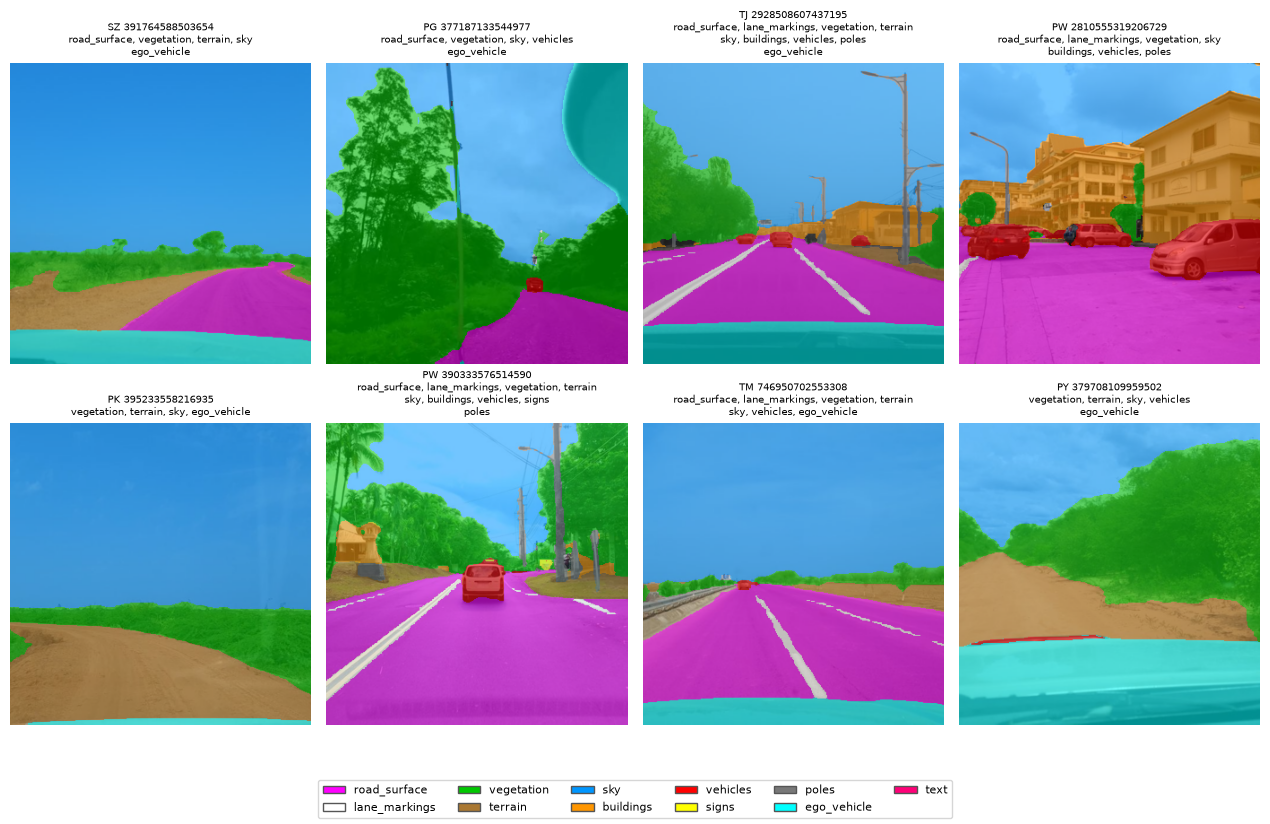

In [37]:
# StreetCLIP with exactly the candidates and prompts of the baseline run
model = GeoCLIPModel(cfg.streetclip_model, cfg)
model.set_candidates(info["labels"], mapper.prompts(info["labels"], info["prompt_template"]))
runner = q3.Q3Runner(q3cfg, cfg, dataset, presence)

# check the masks by eye: random images, as the model sees them
q3.Q3Reporter(None, runner).show_overlays(sample.sample(8, random_state=1)["id"].tolist());

### Q3.0 Masked runs

In [38]:
RUN_Q3 = False       # True once: all images (saved in chunks; after a crash it continues)
if RUN_Q3:
    runner.run(model, sample_ids)          # run name = fill mode ("gray")

q3_rows, q3_logits, q3_settings = q3.Q3Runner.load(runner.run_dir(cfg.fill_mode))
print(f"{q3_rows['id'].nunique():,} images, {len(q3_rows):,} versions")
display(q3.Q3Runner.check_original(q3_rows, q3_logits, q3_settings["labels"], preds, logits))

12,154 images, 437,678 versions


images                12154.000000
top1_agreement            0.998025
max_abs_logit_diff        0.117388
dtype: float64

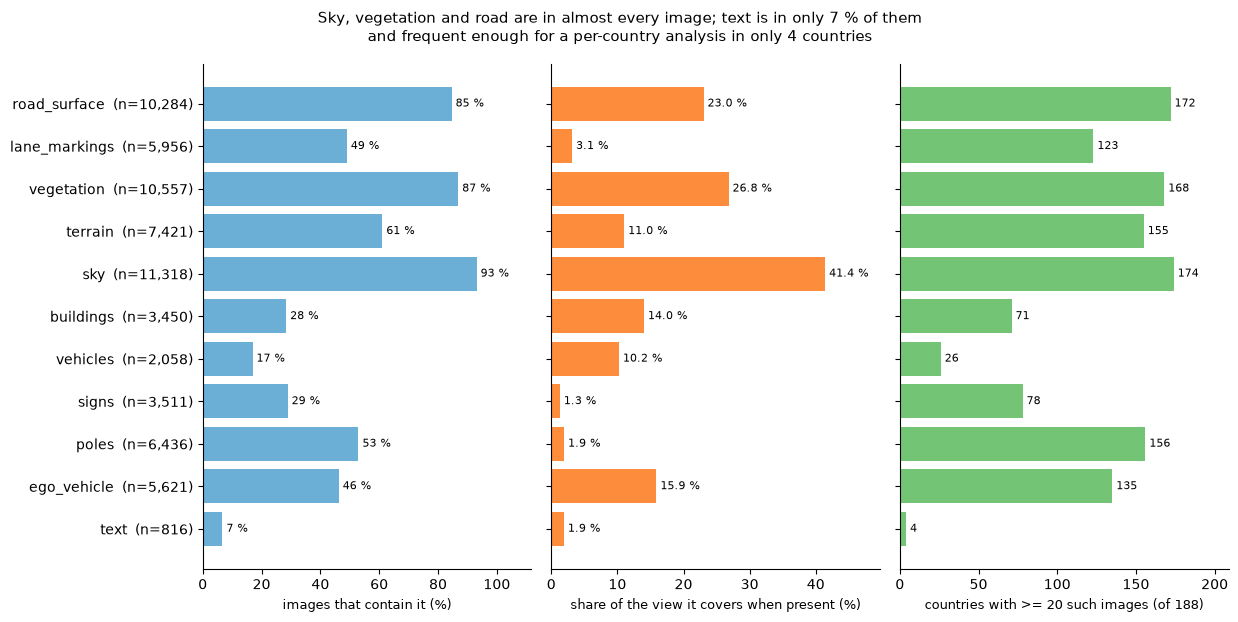

In [39]:
ana3 = q3.Q3Analyser(q3cfg, q3_rows, q3_logits, q3_settings["labels"], sample, mapper.table,
                     presence=presence, baseline_preds=preds)
rep3 = q3.Q3Reporter(ana3, runner)
presence_tab = ana3.presence_overview()    # how often each element is there -> how far we can split by country
rep3.plot_presence(presence_tab,
                   title="Sky, vegetation and road are in almost every image; text is in only 7 % of them\n"
                         "and frequent enough for a per-country analysis in only 4 countries");

### Q3.1 Which elements change the prediction?
- Macro average: every country counts once; pooled (every image) as a supplement
- Table: every hidden condition (real mask, random control, difference with 95 % CI)
- Plots: one row per visual element, same order in both (the parts follow in Q3.2, combinations in Q3.5)

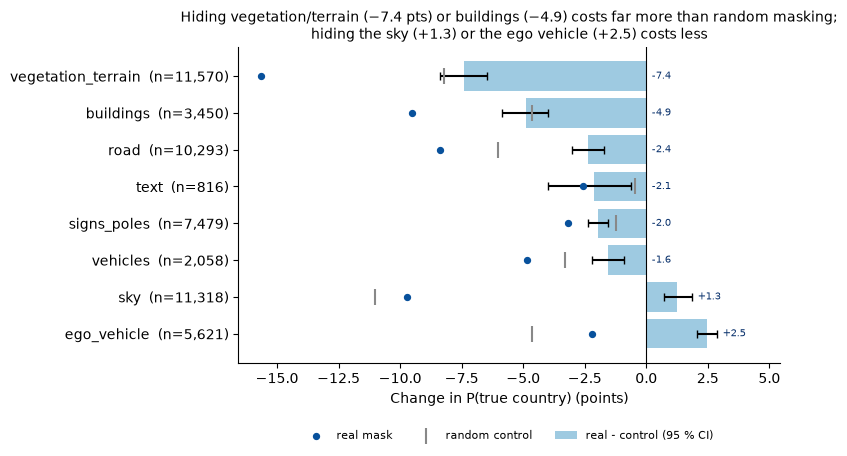

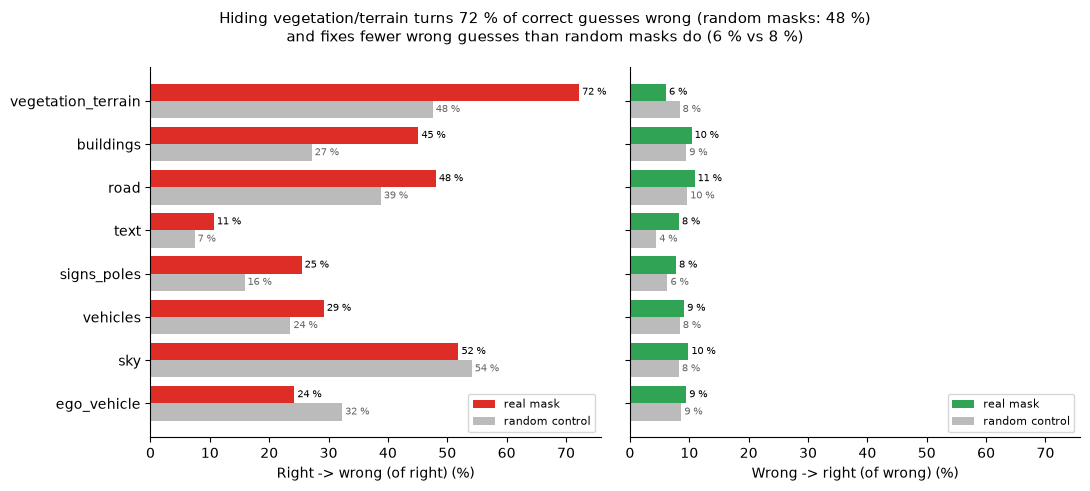

In [42]:
s_macro = ana3.summary()                                   # d_true, d_orig, flip, r2w, w2r
s_pooled = ana3.summary(level="pooled")
#display(rep3.table(s_macro))                               # reference table: all conditions

coarse = q3.subset(s_macro, q3.COARSE)                     # one row per visual element
order = q3.effect_order(coarse)                            # strongest effect on top, used by both plots
rep3.plot_effects(coarse, "d_true", order=order,
                  title="Hiding vegetation/terrain (−7.4 pts) or buildings (−4.9) costs far more than random masking;\n"
                        "hiding the sky (+1.3) or the ego vehicle (+2.5) costs less");
rep3.plot_flips(coarse, order=order,
                title="Hiding vegetation/terrain turns 72 % of correct guesses wrong (random masks: 48 %)\n"
                      "and fixes fewer wrong guesses than random masks do (6 % vs 8 %)");

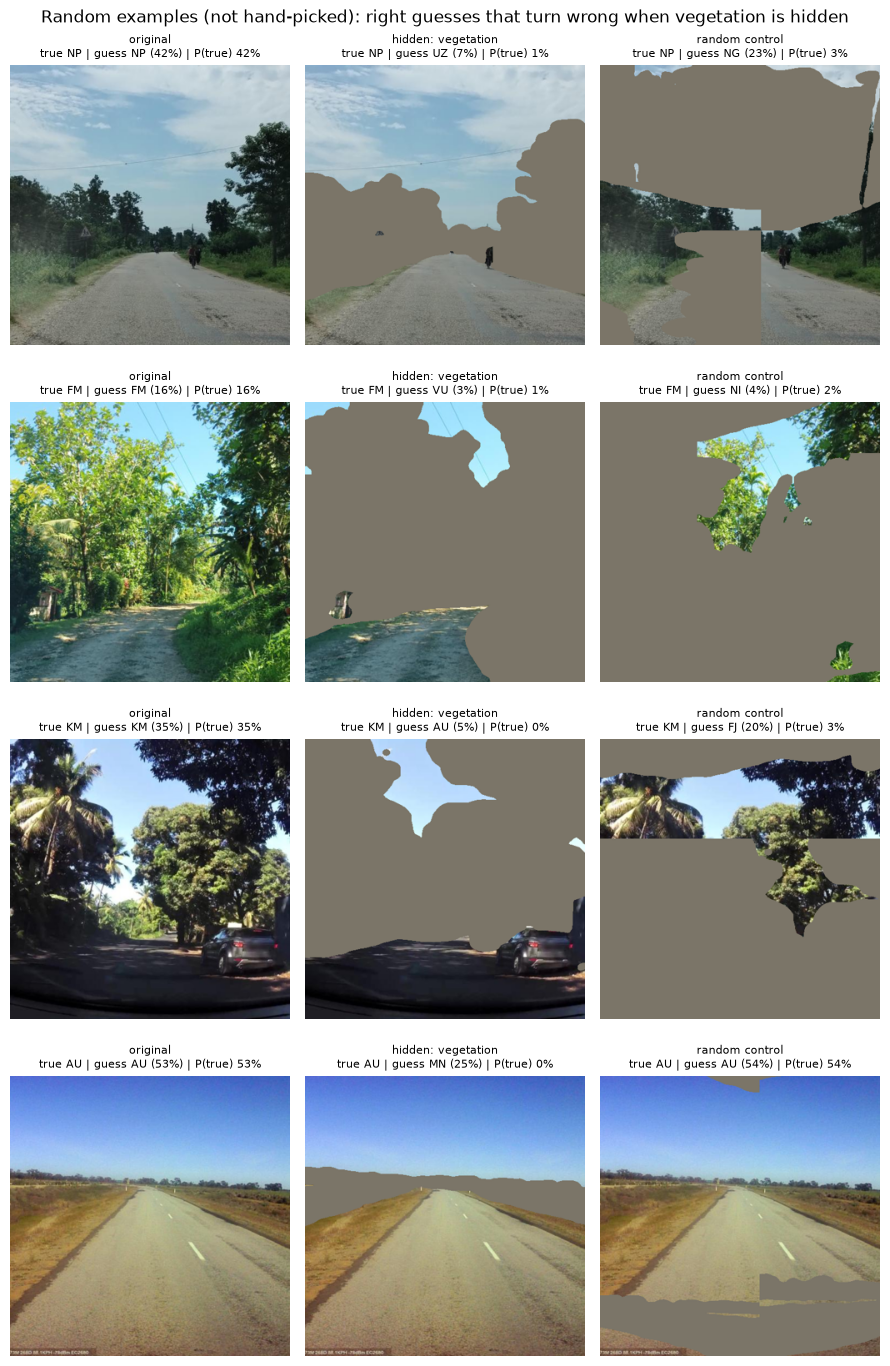

In [41]:
# random examples (not hand-picked): right -> wrong when vegetation, the strongest cue, is hidden
rep3.show_examples("vegetation", which="r2w", n=4);

### Q3.2 Split clues: road surface vs lane markings, signs vs poles, vegetation vs terrain
- Left: each whole element (grey) and its parts; right: effect vs share of the view that is hidden
- The parts occur in different sets of images, so this is not a controlled per-pixel ranking

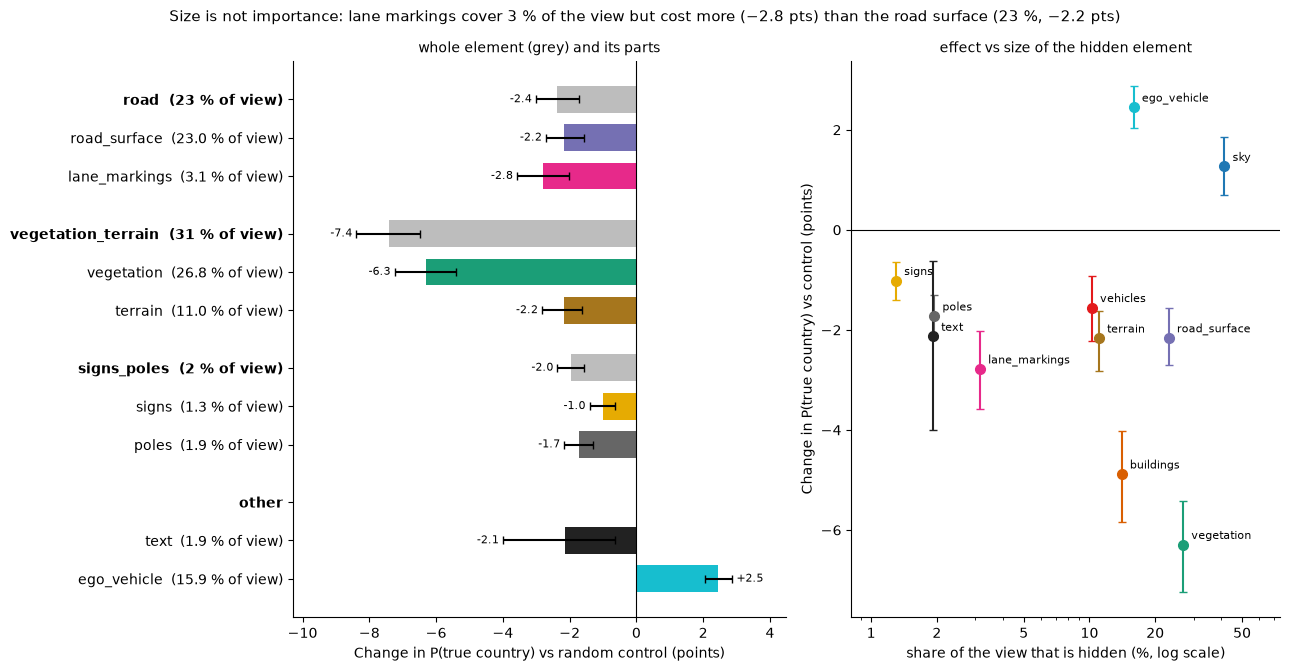

In [43]:
split = ["road", "road_surface", "lane_markings", "vegetation_terrain", "vegetation", "terrain",
         "signs_poles", "signs", "poles", "text", "ego_vehicle", "sky", "buildings", "vehicles"]
rep3.plot_split(q3.subset(s_macro, split),
                title="Size is not importance: lane markings cover 3 % of the view but cost more (−2.8 pts) "
                      "than the road surface (23 %, −2.2 pts)");

### Q3.3 Does the model lose confidence, does its probability spread out?
- `correct0`: images that were right vs wrong before hiding
- Confidence = top-1 probability; entropy = how spread out the probabilities are (bits, higher = less certain)
- Flips and wrong -> right: see Q3.1

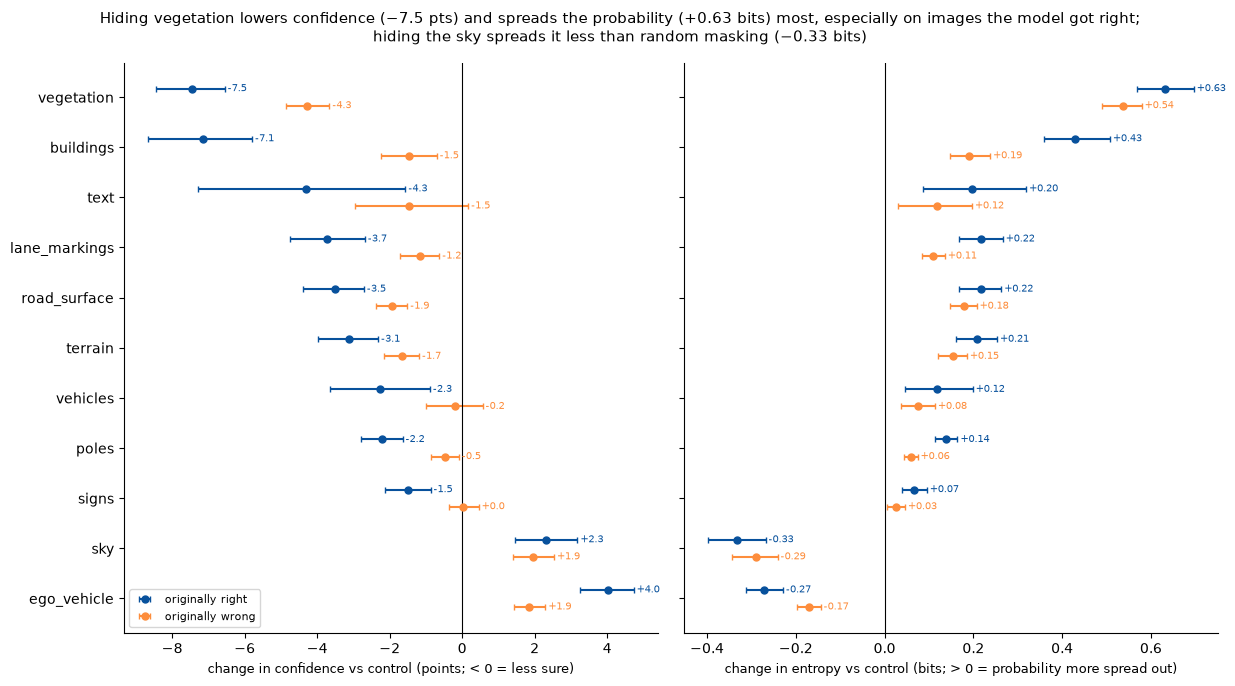

In [44]:
conf = ana3.summary(metrics=("d_conf", "d_entropy"), by="correct0", conditions=list(q3.FINE))
rep3.plot_confidence(conf,
                     title="Hiding vegetation lowers confidence (−7.5 pts) and spreads the probability (+0.63 bits) most, "
                           "especially on images the model got right;\n"
                           "hiding the sky spreads it less than random masking (−0.33 bits)");

### Q3.4 Neighbours and usual confusions
- Where do the new errors land (right -> wrong flips; every flip counts once): a land neighbour, the same
  subregion, or one of the 5 most frequent wrong guesses of the true country (full test set)?
  Dashed line: where the model's own errors on the unmasked images land
- Where does the probability go: true country, its land neighbours, its usual confusions (pooled)
- Which country pairs does hiding an element create (sorted by real minus control)?

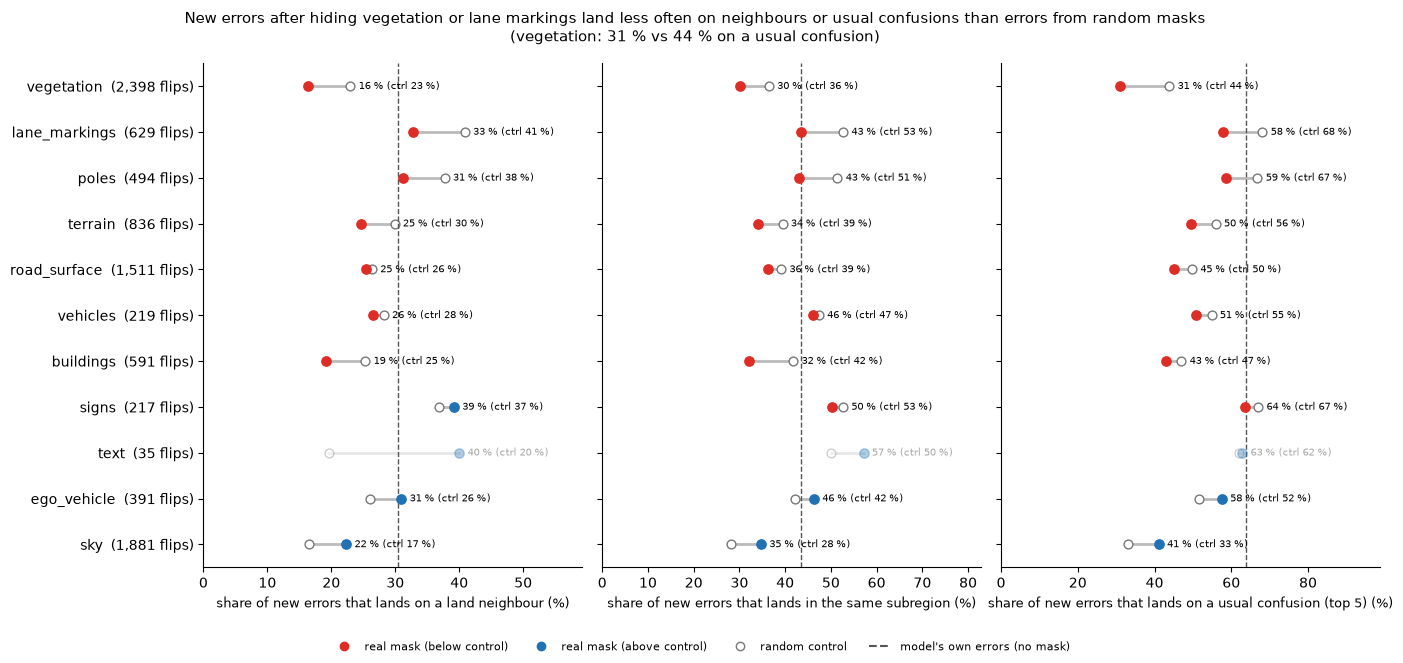

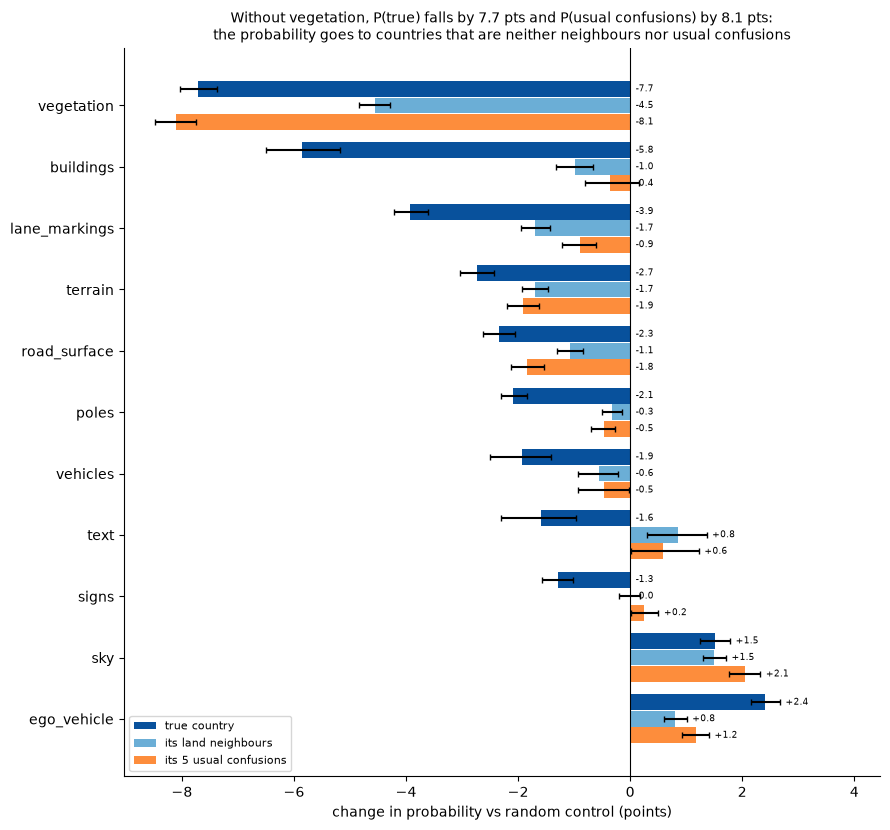

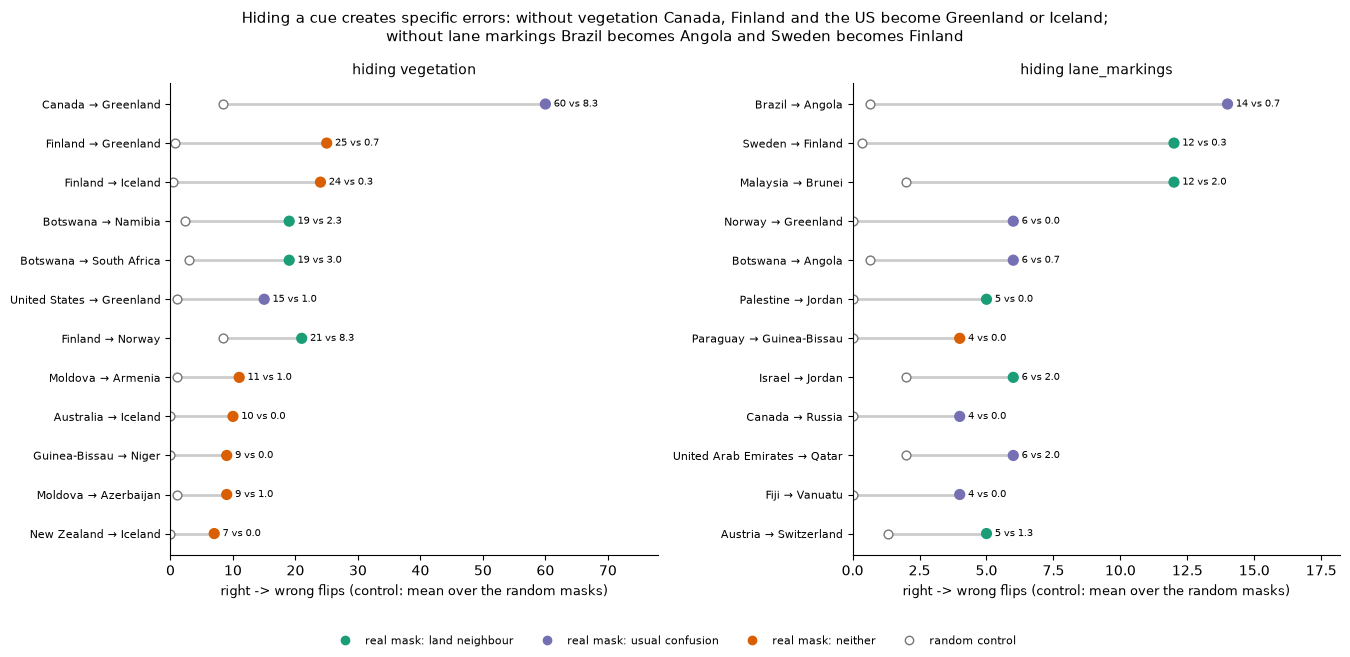

In [45]:
shift = ana3.confusion_shift()                       # pooled
rep3.plot_destinations(shift, conditions=list(q3.FINE),
                       title="New errors after hiding vegetation or lane markings land less often on neighbours or usual "
                             "confusions than errors from random masks\n(vegetation: 31 % vs 44 % on a usual confusion)");

shift_p = ana3.summary(("d_true", "d_nb", "d_sim"), level="pooled", conditions=list(q3.FINE))
rep3.plot_probability_shift(shift_p,
                            title="Without vegetation, P(true) falls by 7.7 pts and P(usual confusions) by 8.1 pts:\n"
                                  "the probability goes to countries that are neither neighbours nor usual confusions");

rep3.plot_flip_pairs(["vegetation", "lane_markings"], top=12,
                     title="Hiding a cue creates specific errors: without vegetation Canada, Finland and the US become "
                           "Greenland or Iceland;\nwithout lane markings Brazil becomes Angola and Sweden becomes Finland");

### Q3.5 Do cues compensate each other?
- extra = effect(both hidden) - (effect A + effect B), control-corrected; > 0 = hiding both hurts more than
  the two alone (when one is hidden, the other still carries the information)

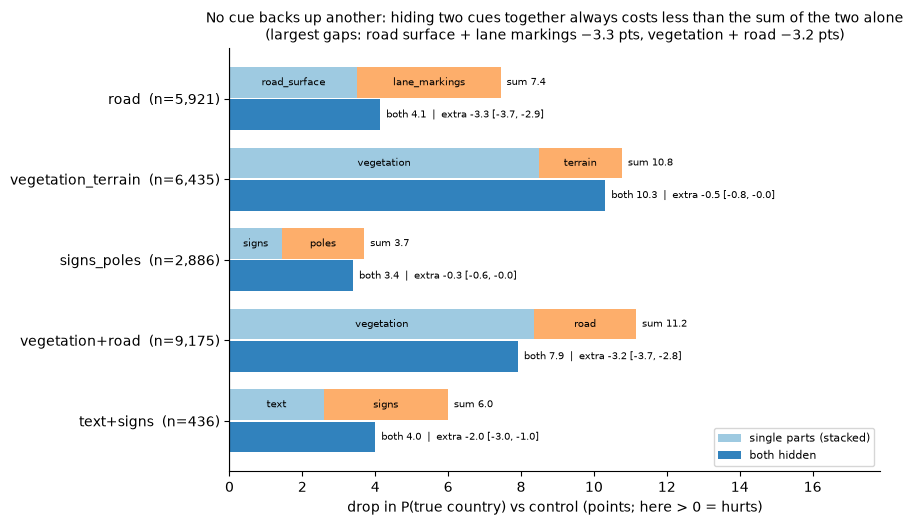

In [46]:
inter = ana3.interactions()
rep3.plot_interactions(inter,
                       title="No cue backs up another: hiding two cues together always costs less than the sum of the two "
                             "alone\n(largest gaps: road surface + lane markings −3.3 pts, vegetation + road −3.2 pts)");

### Q3.6 Which cue matters where?
- Strongest cue per country (control-corrected change of P(true), 95 % CI over camera sequences; hollow = CI crosses 0)
- Country x element for these countries and the 20 focus countries; only cells with >= 20 images containing the element
- Rare elements (text, signs, lane markings): by subregion

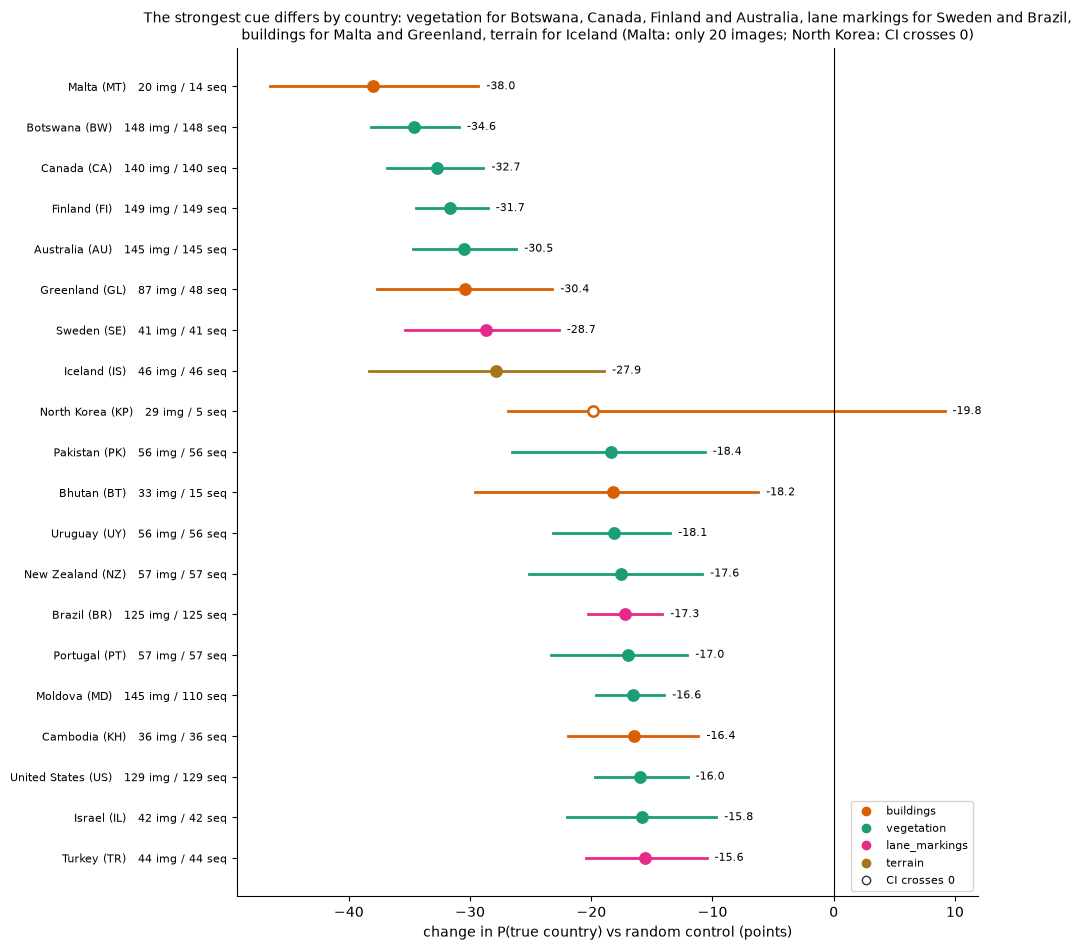

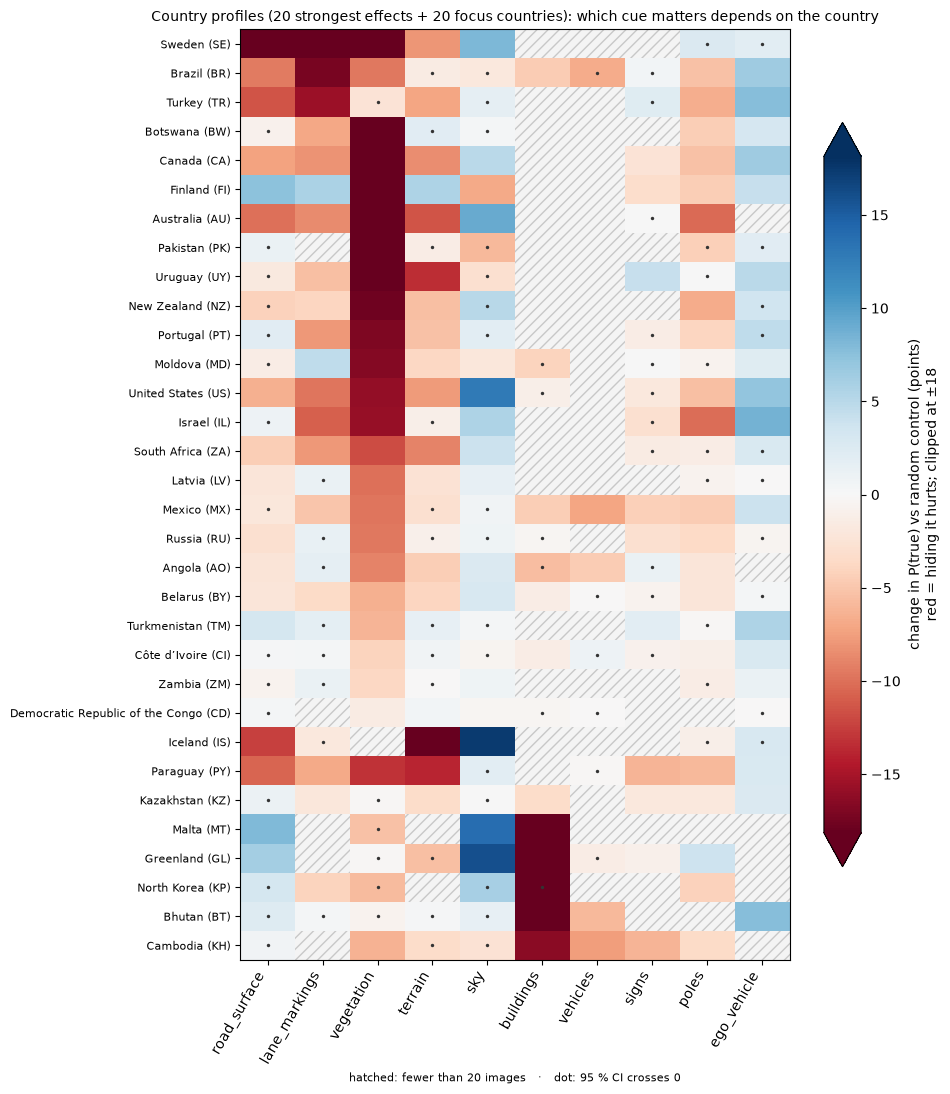

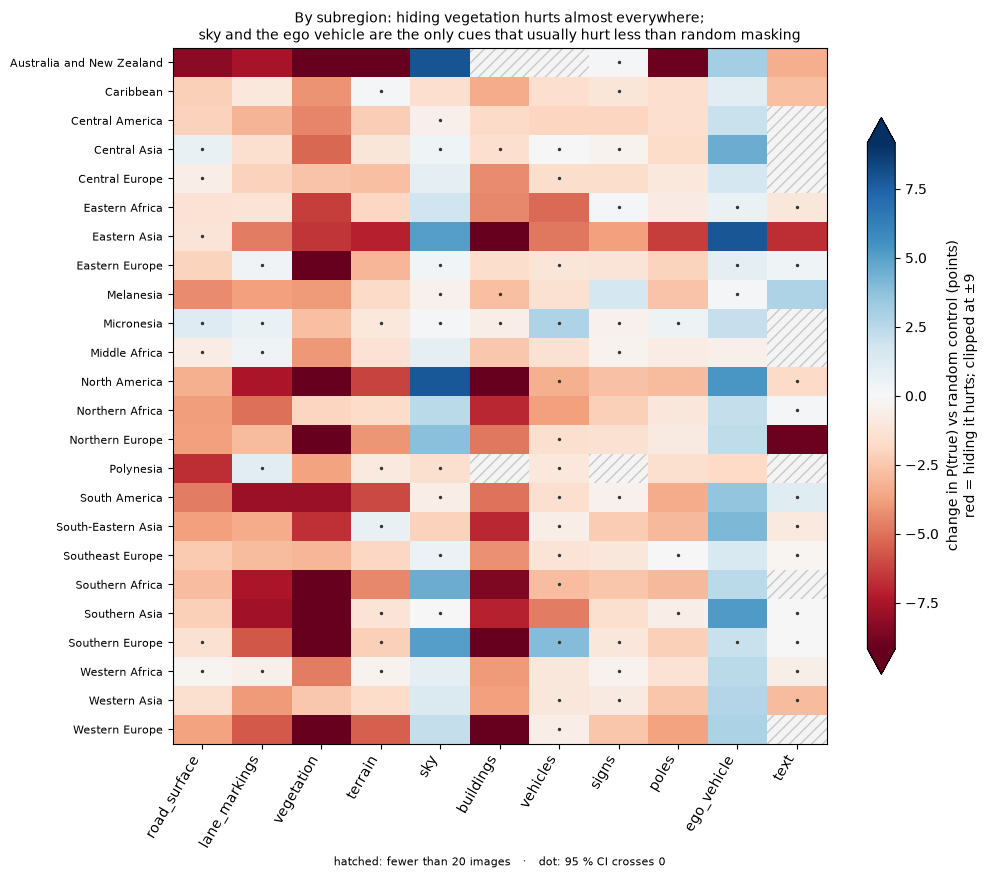

In [47]:
prof = ana3.country_profile("d_true")
cues = ["road_surface", "lane_markings", "vegetation", "terrain", "buildings", "signs", "poles", "text"]
strongest = ana3.strongest_cue(prof, conditions=cues)
rep3.plot_strongest(strongest, top=20,
                    title="The strongest cue differs by country: vegetation for Botswana, Canada, Finland and Australia, "
                          "lane markings for Sweden and Brazil,\nbuildings for Malta and Greenland, terrain for Iceland "
                          "(Malta: only 20 images; North Korea: CI crosses 0)");

show = list(dict.fromkeys(list(strongest.index[:20]) + list(q3cfg.focus_countries)))
rep3.plot_heatmap(prof, conditions=[c for c in q3.FINE if c != "text"], rows=show, sort_by="strongest",
                  title="Country profiles (20 strongest effects + 20 focus countries): which cue matters depends on the country");

prof_sub = ana3.country_profile("d_true", group="world_subregion")
rep3.plot_heatmap(prof_sub, conditions=list(q3.FINE),
                  title="By subregion: hiding vegetation hurts almost everywhere;\n"
                        "sky and the ego vehicle are the only cues that usually hurt less than random masking");

### Q3.7 Does the effect change by environment?
- Same idea as Q4: environment and country are mixed up, so next to the pooled effect (left) the plots show the
  within-country difference (right: category effect minus the country's own effect, averaged over countries)

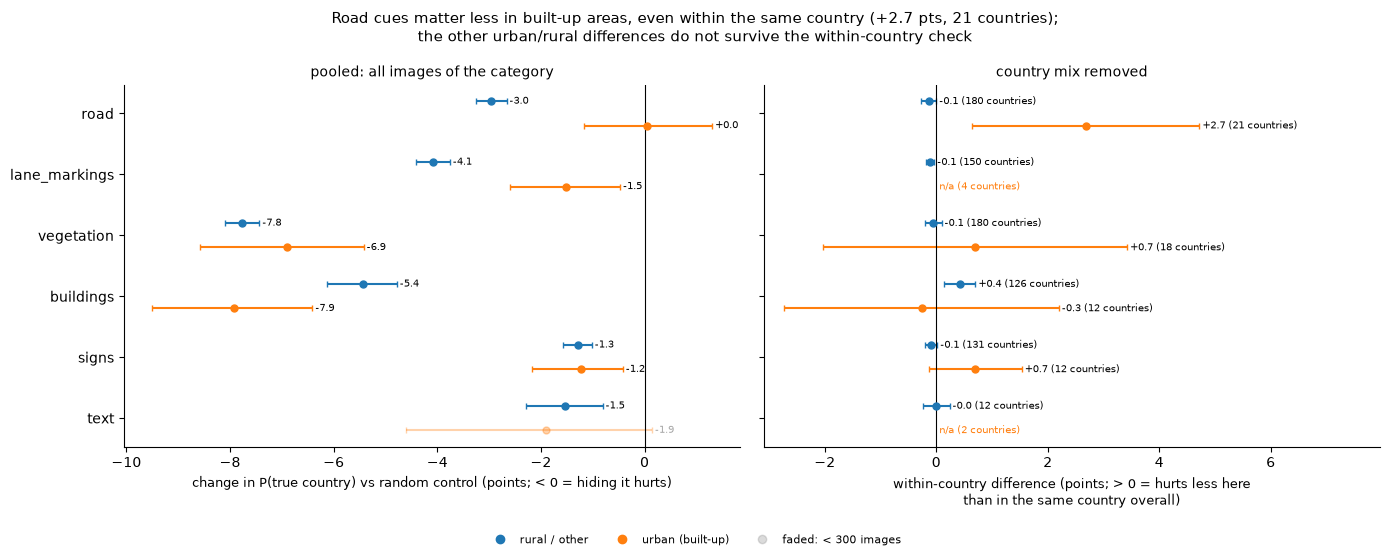

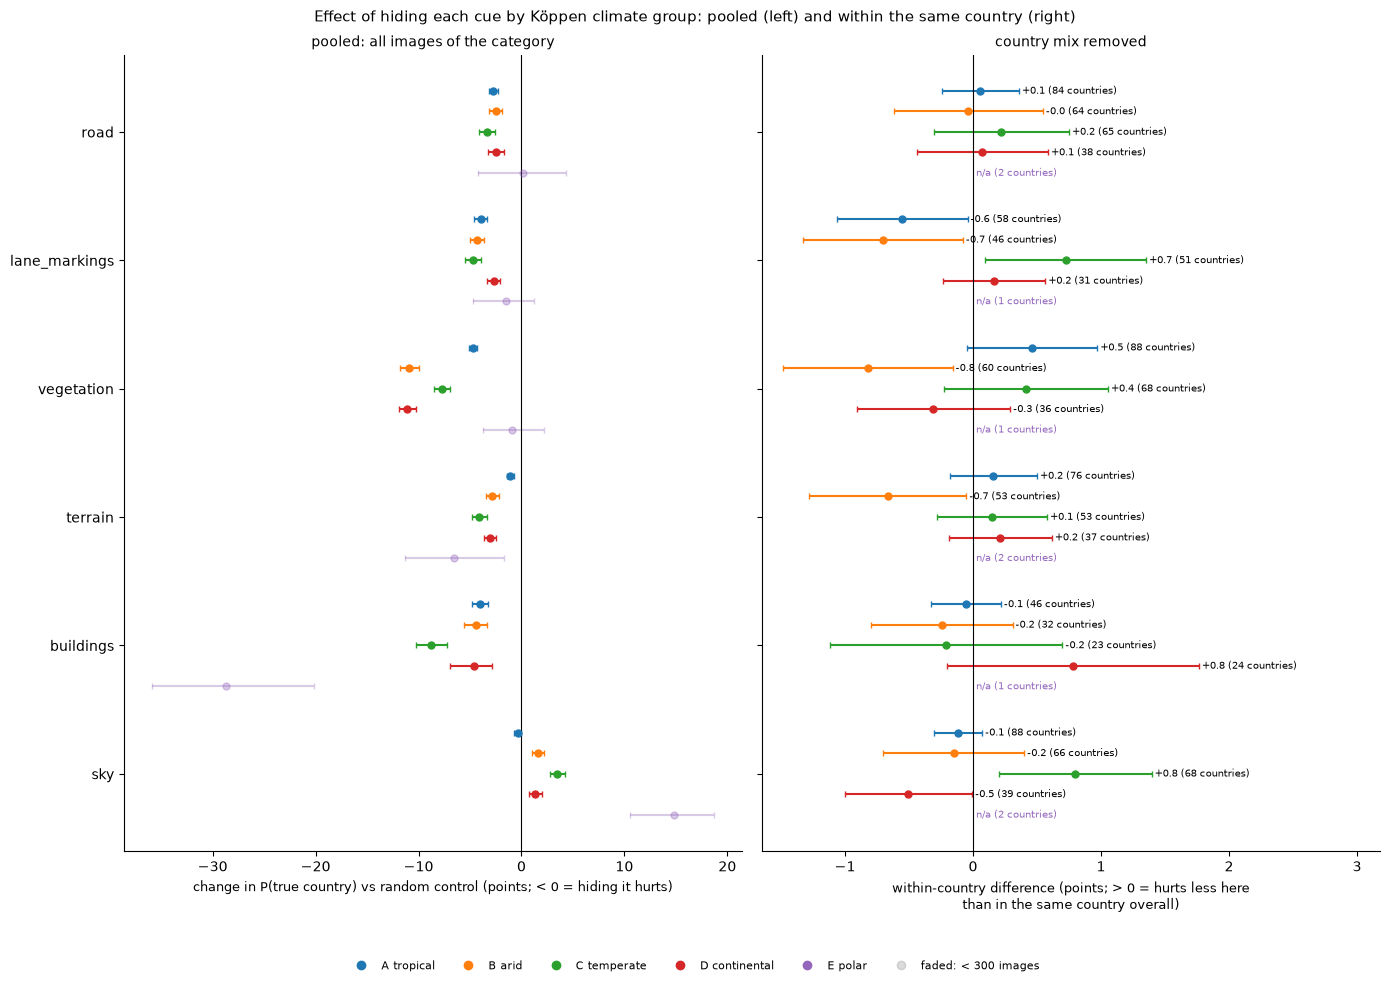

In [48]:
from pair_a import q4_environment as q4
env = q4.add_env_columns(preds)
urban_eff = ana3.environment(env, "urban")
rep3.plot_environment(urban_eff, "urban",
                      conditions=["road", "lane_markings", "vegetation", "buildings", "signs", "text"],
                      title="Road cues matter less in built-up areas, even within the same country (+2.7 pts, 21 countries);\n"
                            "the other urban/rural differences do not survive the within-country check");
climate_eff = ana3.environment(env, "climate_group")
rep3.plot_environment(climate_eff, "climate_group",
                      conditions=["road", "lane_markings", "vegetation", "terrain", "buildings", "sky"],
                      title="Effect of hiding each cue by Köppen climate group: pooled (left) and within the same country (right)");

In [49]:
del model
free_gpu_memory()

### Q3 findings
- **Hidden cues matter beyond "less image".** Hiding vegetation/terrain lowers P(true country) by 7.4 pts more than
  a random mask of the same size, buildings by 4.9 pts; 72 % of correct guesses turn wrong without vegetation/terrain
  (random masks: 48 %). Hiding the sky (+1.3 pts) or the ego vehicle (+2.5 pts) hurts *less* than random masking.
- **Size is not importance.** Lane markings cover 3 % of the view but cost 2.8 pts, more than the road surface
  (23 % of the view, 2.2 pts).
- **Less certainty.** Without vegetation the model is less sure (−7.5 pts confidence on images it got right) and its
  probability is more spread out (+0.63 bits).
- **Different errors.** New errors after hiding vegetation land less often on usual confusions than errors from random
  masks (31 % vs 44 %); specific pairs appear (Canada → Greenland 60 vs 8.3, Finland → Iceland 24 vs 0.3; without lane
  markings Brazil → Angola 14 vs 0.7).
- **No backup between cues.** Hiding two cues together always costs less than the sum of the two alone (road surface +
  lane markings: −3.3 pts): the cues overlap or the damage saturates.
- **Country-dependent.** Strongest cue: vegetation for Botswana (−34.6 pts), Canada (−32.7), Finland (−31.7) and
  Australia (−30.5); lane markings for Sweden (−28.7) and Brazil (−17.3); terrain for Iceland (−27.9). Malta (20 images)
  and North Korea (5 sequences, CI crosses 0) are weak evidence.
- **Environment: be careful.** Road cues matter less in built-up areas even within countries (+2.7 pts, 21 countries);
  the urban/rural gaps for vegetation and buildings disappear in the within-country check.
- **Limits.** Gray masks, segmentation errors (e.g. dirt roads labelled as terrain) and overlapping cues: the results
  show how sensitive the model is to these interventions, not proof that it relies on the cue causally.

## Q4: Environment
Do accuracy and confidence vary with climate, land cover, distance to the sea, or urban vs. rural setting?
- Problem: environment and country are mixed up (a climate is mostly a few countries)
- **Expected from country mix**: accuracy we would get if only the country mattered
  (each image gets the accuracy of its country; big countries count more)
- **Within-country difference**: category accuracy minus its own country's accuracy, every country counts once
- Actual close to expected: the country mix explains it, not the environment

In [ ]:
from pair_a import q4_environment as q4

env = q4.add_env_columns(preds)   # adds climate_group, urban (built-up or not), sea_bin

### Q4.1 Land cover
- First: who is in each class? Then: actual vs. expected accuracy

In [ ]:
lc = q4.effect_table(env, "land_cover_name").drop(index="no data")
display(q4.show_effects(lc))
q4.plot_country_mix(env[env.land_cover_name != "no data"], "land_cover_name",
                    "Who is in each land cover class? Half of \"sparse vegetation\" is Australia").show()
q4.plot_expected(lc, "Land cover: built-up areas beat their country mix by 9 points; most classes stay within 3").show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
artificial surfaces,"10,392",136,60.5 %,59.6 to 61.4 %,51.9 %,+8.6 pts,+6.7 pts,73.0 %
bare soil,"10,745",81,33.4 %,32.5 to 34.3 %,35.6 %,-2.2 pts,-6.6 pts,36.4 %
cropland,"71,833",169,50.9 %,50.6 to 51.3 %,49.1 %,+1.9 pts,+1.6 pts,58.8 %
grassland,"22,977",152,49.4 %,48.7 to 50.0 %,49.8 %,-0.4 pts,-1.9 pts,36.4 %
"herbaceous, flooded","2,639",52,55.6 %,53.7 to 57.5 %,57.6 %,-2.0 pts,-0.6 pts,43.8 %
mangroves,191,29,42.9 %,36.1 to 50.0 %,44.2 %,-1.3 pts,,
shrubs,"19,622",110,44.3 %,43.6 to 45.0 %,45.3 %,-1.1 pts,-3.6 pts,39.1 %
snow and glaciers,91,8,75.8 %,66.1 to 83.5 %,59.4 %,+16.4 pts,,
sparse vegetation,"9,467",65,71.5 %,70.6 to 72.4 %,70.4 %,+1.1 pts,-4.6 pts,38.7 %
tree covered,"53,791",161,51.6 %,51.2 to 52.0 %,54.2 %,-2.6 pts,-5.2 pts,36.9 %


### Q4.2 Climate
- Köppen main groups (A tropical ... E polar)

In [ ]:
groups_order = list(q4.CLIMATE_GROUPS.values())
cl = q4.effect_table(env, "climate_group")
display(q4.show_effects(cl))
q4.plot_country_mix(env, "climate_group", "Who is in each climate group?", order=groups_order).show()
q4.plot_expected(cl, "Climate: A to D are within 1.5 points of what the country mix predicts", order=groups_order).show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
A tropical,"52,436",99,38.2 %,37.8 to 38.6 %,39.6 %,-1.4 pts,-2.3 pts,29.1 %
B arid,"52,654",88,51.5 %,51.1 to 52.0 %,50.4 %,+1.1 pts,-0.8 pts,40.5 %
C temperate,"50,087",100,52.6 %,52.2 to 53.0 %,53.5 %,-0.8 pts,-0.6 pts,45.7 %
D continental,"48,590",60,61.2 %,60.8 to 61.6 %,59.8 %,+1.4 pts,-2.6 pts,45.7 %
E polar,"1,876",27,63.1 %,60.9 to 65.2 %,69.4 %,-6.3 pts,-14.8 pts,25.0 %


### Q4.3 Distance to the sea
- `dist_sea`: 0 = at the coast, 1 = far inland (capped; landlocked countries have median 1.0)
- OSV-5M does not document the unit, so we use fixed bins

In [ ]:
sea = q4.effect_table(env, "sea_bin")
display(q4.show_effects(sea))
q4.plot_expected(sea, "Distance to the sea: small effects (coast -4 points, far inland +3), mostly in big countries",
                 order=q4.SEA_LABELS).show()

,Images,Countries,Accuracy,95 % CI,Expected from country mix,Actual - expected,Within-country difference,Countries above own average
0-0.05 (coast),"24,629",144,50.5 %,49.9 to 51.1 %,54.9 %,-4.4 pts,-1.8 pts,35.8 %
0.05-0.25,"28,153",136,53.4 %,52.9 to 54.0 %,53.7 %,-0.2 pts,+0.6 pts,44.9 %
0.25-0.5,"17,831",116,51.9 %,51.1 to 52.6 %,53.8 %,-1.9 pts,-0.1 pts,51.1 %
0.5-0.9,"28,892",115,49.6 %,49.0 to 50.2 %,51.1 %,-1.5 pts,-0.9 pts,44.3 %
0.9-0.99,"25,827",92,51.1 %,50.5 to 51.7 %,51.9 %,-0.8 pts,-0.8 pts,52.5 %
0.99-1 (inland),"82,982",90,50.1 %,49.7 to 50.4 %,47.5 %,+2.6 pts,-0.0 pts,47.4 %


### Q4.4 Urban vs. rural
- No urban column in OSV-5M. Proxy: land cover "artificial surfaces" (built-up area)
- `road_index` is not usable: it has only one value per country
- Check: one vote per camera sequence, so a long drive does not count many times

In [ ]:
ur = q4.effect_table(env, "urban")
ur_seq = q4.effect_table(q4.per_sequence(env, "urban"), "urban")
display(q4.show_effects(pd.concat({"per image": ur, "per sequence": ur_seq})))

- Per country (>= 20 images in both groups); grey rows: fewer than 10 built-up sequences (weak evidence, not on the map)

Country,Built-up images,Built-up sequences,Accuracy built-up,Accuracy other,Difference
Peru,39,14,12.8 %,48.3 %,-35.5 pts
Botswana,26,14,50.0 %,82.2 %,-32.2 pts
Papua New Guinea,26,12,7.7 %,36.2 %,-28.6 pts
Angola,36,14,8.3 %,26.6 %,-18.2 pts
Algeria,148,64,18.9 %,32.7 %,-13.8 pts


Country,Built-up images,Built-up sequences,Accuracy built-up,Accuracy other,Difference
Egypt,47,37,55.3 %,20.8 %,+34.5 pts
Senegal,25,16,44.0 %,6.8 %,+37.2 pts
China,762,301,84.4 %,43.9 %,+40.5 pts
Afghanistan,100,20,97.0 %,35.2 %,+61.8 pts
Libya,54,7,92.6 %,24.4 %,+68.1 pts


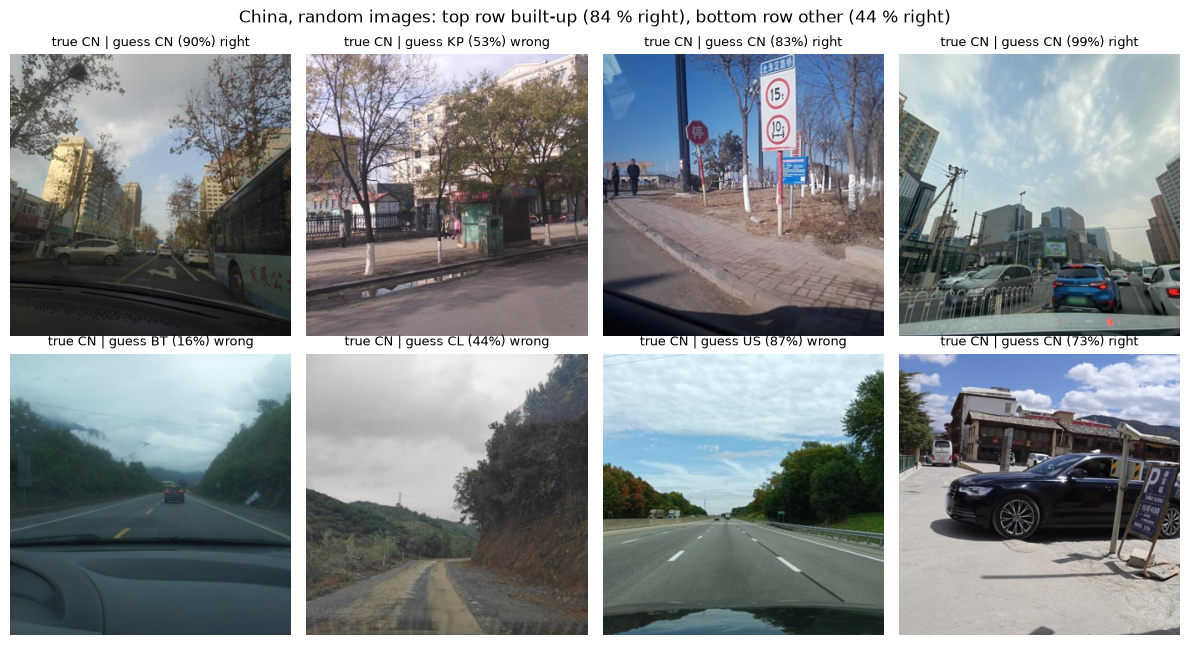

In [ ]:
urb = q4.urban_table(env, mapper.table)
urb_cols = {"name": "Country", "size_urban": "Built-up images", "seq_urban": "Built-up sequences",
            "mean_urban": "Accuracy built-up", "mean_rural": "Accuracy other", "diff": "Difference"}
for part in [urb.head(5), urb.tail(5)]:   # worst and best for built-up areas
    display(viz.show_table(part, urb_cols, pct=["mean_urban", "mean_rural"], pts=["diff"],
                           grey=part.seq_urban < q4.MIN_SEQ, index=False))
q4.plot_urban_map(urb).show()
viz.image_grid(dataset, q4.urban_examples(env, "CN"),
               "China, random images: top row built-up (84 % right), bottom row other (44 % right)");

### Q4 findings
- **Climate:** raw accuracy differs a lot (A tropical 38 %, D continental 61 %), but A to D are within 1.5 points of what their country mix predicts. Inside countries the difference is also small (within 3 points). Only E polar is lower (-6 points vs. expected, -15 within-country), but with few images and only 12 countries. So the climate effect is mostly the country mix.
- **Land cover:** most classes stay within 3 points of their country mix. "sparse vegetation" looks easy (72 %) only because half of it is Australia. Clear exception: built-up areas (+8.6 points vs. expected, +6.7 within-country). Water bodies are worse (-5.5 / -4.0).
- **Bare soil:** looks very hard (33 %), but its country mix already predicts 36 %. Within-country it is -6.6 points, so smaller countries drop more there.
- **Distance to the sea:** small effects. The coast is worse (-4.4 points vs. expected, -4.2 with one vote per sequence), far inland is a bit better (+2.6). Mostly big countries: US coast images are 38 % right, the US overall 63 %. With every country counted once the effect is small (-1.8 +/- 2.3 points).
- **Urban vs. rural:** built-up areas are better than the country average in 73 % of 74 countries (+6.7 points). This also holds with one vote per camera sequence (+8.3 points, 52 countries). Very large values for single countries (Libya, Afghanistan) come from only a few sequences.
- **Confidence:** moves with accuracy, but less (built-up: confidence +4.6 points, accuracy +6.7). Bare soil has the largest gap between confidence and accuracy (0.118, overconfident).
- `road_index` has one value per country, so it cannot measure urban vs. rural.
- Open questions: does the urban advantage come from text and signs (the Q3 masking can test this)? Why are US coast images so hard?